# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [5]:
# Count missing values
display(mammals_df.isnull().sum())

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

In [3]:
# Display the first five rows
display(mammals_df.head())

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
# Display the last five rows
display(mammals_df.tail())

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [7]:
mammals_df.shape

(62, 11)

In [6]:
# Inspect data types and non-missing values
mammals_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     str    
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), str(1)
memory usage: 5.5 KB


In [8]:
mammals_df.isnull().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer:

Each row represents one mammal species and its recorded characteristics, including sleep duration, body weight, brain weight, lifespan, gestation time, and danger ratings.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` |  |  |  |
| `non_dreaming_sleep` |  |  |  |
| `dreaming_sleep` |  |  |  |
| `body_weight` |  |  |  |
| `brain_weight` |  |  |  |
| `max_life_span` |  |  |  |
| `gestation_time` |  |  |  |
| `predation_index` |  |  |  |
| `sleep_exposure_index` |  |  |  |
| `danger_index` |  |  |  |
| `total_sleep` |  |  |  |

Your answer:

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

Dreaming and non-dreaming sleep are expected to have a positive relationship, meaning mammals that spend more time in one phase may also spend more time in the other. I predict that non-dreaming sleep will have the stronger linear relationship with total sleep because it generally makes up a larger portion of daily sleep.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer:

I predict that dreaming and non-dreaming sleep will have a moderately positive relationship. I expect dreaming sleep and total sleep to have a strong positive relationship, while non-dreaming sleep and total sleep will have an even stronger positive relationship. I believe non-dreaming sleep will be more strongly related to total sleep because it generally accounts for a larger portion of a mammal's daily sleep.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [10]:
# Create a dataset with complete records
sleep_df = mammals_df.dropna(
    subset=[
        "dreaming_sleep",
        "non_dreaming_sleep",
        "total_sleep",
        "danger_index",
        "predation_index"
    ]
).copy()

# Check the number of records
print("Original records:", len(mammals_df))
print("Complete records:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

# Check sleep measurement ranges
sleep_columns = [
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep"
]

display(sleep_df[sleep_columns].agg(["min", "max"]))

# Verify all sleep measurements are between 0 and 24 hours
valid_sleep = (
    (sleep_df[sleep_columns] >= 0) &
    (sleep_df[sleep_columns] <= 24)
).all().all()

print("All sleep values within 0–24 hours:", valid_sleep)

Original records: 62
Complete records: 48
Records removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


All sleep values within 0–24 hours: True


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

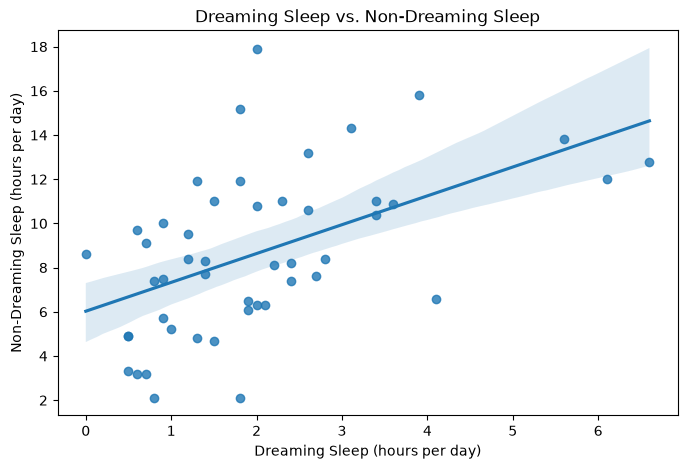

In [11]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="non_dreaming_sleep"
)

plt.title("Dreaming Sleep vs. Non-Dreaming Sleep")
plt.xlabel("Dreaming Sleep (hours per day)")
plt.ylabel("Non-Dreaming Sleep (hours per day)")
plt.show()

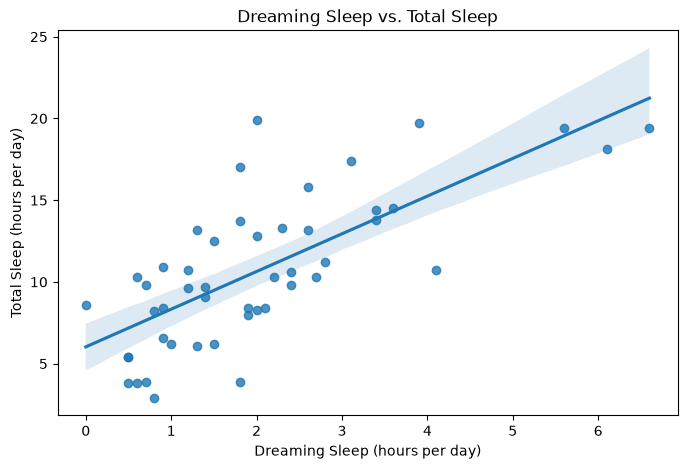

In [12]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep"
)

plt.title("Dreaming Sleep vs. Total Sleep")
plt.xlabel("Dreaming Sleep (hours per day)")
plt.ylabel("Total Sleep (hours per day)")
plt.show()

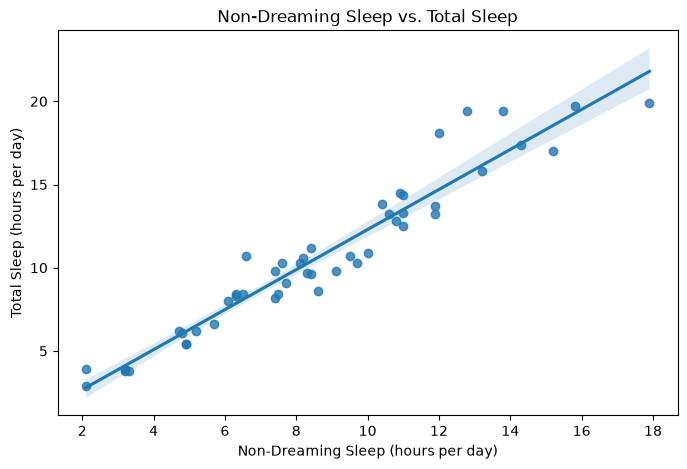

In [13]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep"
)

plt.title("Non-Dreaming Sleep vs. Total Sleep")
plt.xlabel("Non-Dreaming Sleep (hours per day)")
plt.ylabel("Total Sleep (hours per day)")
plt.show()

In [14]:
# Define the three relationships
relationships = [
    ("dreaming_sleep", "non_dreaming_sleep"),
    ("dreaming_sleep", "total_sleep"),
    ("non_dreaming_sleep", "total_sleep")
]

# Calculate correlation and R-squared
for x, y in relationships:
    correlation = sleep_df[x].corr(sleep_df[y])
    r_squared = correlation ** 2

    print(f"{x} vs. {y}")
    print(f"Correlation (r): {correlation:.4f}")
    print(f"R-squared: {r_squared:.4f}")
    print()

dreaming_sleep vs. non_dreaming_sleep
Correlation (r): 0.5143
R-squared: 0.2645

dreaming_sleep vs. total_sleep
Correlation (r): 0.7271
R-squared: 0.5287

non_dreaming_sleep vs. total_sleep
Correlation (r): 0.9627
R-squared: 0.9268



**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:

All three scatterplots show positive relationships, with points generally rising from left to right.

Dreaming versus non-dreaming sleep shows a moderate positive linear relationship (r = 0.5143, R² = 0.2645). The points are widely scattered, with some unusual observations, including mammals with approximately 2 hours of dreaming sleep and nearly 18 hours of non-dreaming sleep.

Dreaming versus total sleep shows a stronger positive linear relationship (r = 0.7271, R² = 0.5287). The points follow an approximately straight pattern but still show noticeable variation and a few unusual observations.

Non-dreaming versus total sleep has the strongest positive linear relationship (r = 0.9627, R² = 0.9268). The points closely follow a straight, upward-sloping pattern, with only a few observations farther from the line.

The non-dreaming versus total sleep plot is best summarized by a straight line. Its R-squared of 0.9268 means that approximately 92.7% of the variation in total sleep is explained by the linear relationship with non-dreaming sleep in this dataset. This supports my prediction that non-dreaming sleep would have the stronger relationship with total sleep.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [15]:
# Calculate the sum of both sleep phases
sleep_df["phase_sum"] = (
    sleep_df["dreaming_sleep"] +
    sleep_df["non_dreaming_sleep"]
)

# Check whether the sum agrees with total sleep
sleep_df["sum_matches"] = np.isclose(
    sleep_df["phase_sum"],
    sleep_df["total_sleep"]
)

# Display the results
print("All sleep-phase sums match:", sleep_df["sum_matches"].all())

print("Number of matching records:", sleep_df["sum_matches"].sum())
print("Total records:", len(sleep_df))

# Display several original records
display(
    sleep_df[
        ["species", "dreaming_sleep", "non_dreaming_sleep",
         "phase_sum", "total_sleep", "sum_matches"]
    ].head(10)
)

All sleep-phase sums match: True
Number of matching records: 48
Total records: 48


,species,dreaming_sleep,non_dreaming_sleep,phase_sum,total_sleep,sum_matches
1,African giant pouched rat,2.0,6.3,8.3,8.3,True
4,Asian elephant,1.8,2.1,3.9,3.9,True
5,Baboon,0.7,9.1,9.8,9.8,True
6,Big brown bat,3.9,15.8,19.7,19.7,True
7,Brazilian tapir,1.0,5.2,6.2,6.2,True
8,Cat,3.6,10.9,14.5,14.5,True
9,Chimpanzee,1.4,8.3,9.7,9.7,True
10,Chinchilla,1.5,11.0,12.5,12.5,True
11,Cow,0.7,3.2,3.9,3.9,True
12,Desert hedgehog,2.7,7.6,10.3,10.3,True


In [16]:
# Find the three mammals with the longest non-dreaming sleep
longest_sleep = sleep_df.nlargest(3, "non_dreaming_sleep")

# Display their measurements
display(
    longest_sleep[
        ["species", "dreaming_sleep",
         "non_dreaming_sleep", "total_sleep"]
    ]
)

,species,dreaming_sleep,non_dreaming_sleep,total_sleep
32,Little brown bat,2.0,17.9,19.9
6,Big brown bat,3.9,15.8,19.7
41,Owl monkey,1.8,15.2,17.0


All 48 records passed the sleep-phase sum check, confirming that dreaming sleep plus non-dreaming sleep equals total sleep within normal floating-point rounding.

The three mammals with the longest non-dreaming sleep were the Little brown bat (17.9 hours), Big brown bat (15.8 hours), and Owl monkey (15.2 hours). Their total sleep times were 19.9, 19.7, and 17.0 hours, respectively.

These values agree with the points on the non-dreaming versus total sleep scatterplot. The three mammals appear toward the upper-right portion of the graph, confirming that the plotted measurements match the original records.

## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer:

Yes, mammals that spend more time in dreaming sleep generally spend more time in non-dreaming sleep. The relationship is moderately positive (r = 0.5143, R² = 0.2645). Dreaming sleep also has a positive relationship with total sleep (r = 0.7271, R² = 0.5287).

However, non-dreaming sleep has the strongest linear relationship with total sleep (r = 0.9627, R² = 0.9268). Its scatterplot shows points closely following an upward-sloping straight line, explaining approximately 92.7% of the variation in total sleep through the linear model.

These results support my original prediction that non-dreaming sleep would have the stronger relationship with total sleep.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:

One limitation is that 14 of the original 62 mammal records were excluded because of missing sleep measurements, which could affect how representative the results are. Another limitation is that total sleep is calculated by adding dreaming and non-dreaming sleep, so a strong correlation with either phase is partly expected.

A stronger correlation does not automatically provide a better scientific explanation because correlation does not establish causation. The strong relationship between non-dreaming and total sleep is partly mathematical and does not prove that non-dreaming sleep independently causes mammals to sleep longer.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

I predict that danger and predation categories may provide some additional information about total sleep, but non-dreaming sleep will remain the strongest predictor.

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer:

I predict that both the danger index and predation index will add only a small amount of information. I would look for differences in total sleep between mammals with similar non-dreaming-sleep durations but different danger or predation ratings. If the categories form separate patterns, they may provide additional information.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [17]:
# Count mammals at each danger level (1-5)
print("Danger Index Counts:")
print(
    sleep_df["danger_index"]
    .value_counts()
    .reindex(range(1, 6), fill_value=0)
    .sort_index()
)

# Count mammals at each predation level (1-5)
print("\nPredation Index Counts:")
print(
    sleep_df["predation_index"]
    .value_counts()
    .reindex(range(1, 6), fill_value=0)
    .sort_index()
)

Danger Index Counts:
danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

Predation Index Counts:
predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64


In [18]:
# Create a cross-tabulation of danger and predation ratings
danger_predation_table = pd.crosstab(
    sleep_df["danger_index"],
    sleep_df["predation_index"]
)

# Include all five levels in their natural order
danger_predation_table = danger_predation_table.reindex(
    index=range(1, 6),
    columns=range(1, 6),
    fill_value=0
)

# Display the table
display(danger_predation_table)

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

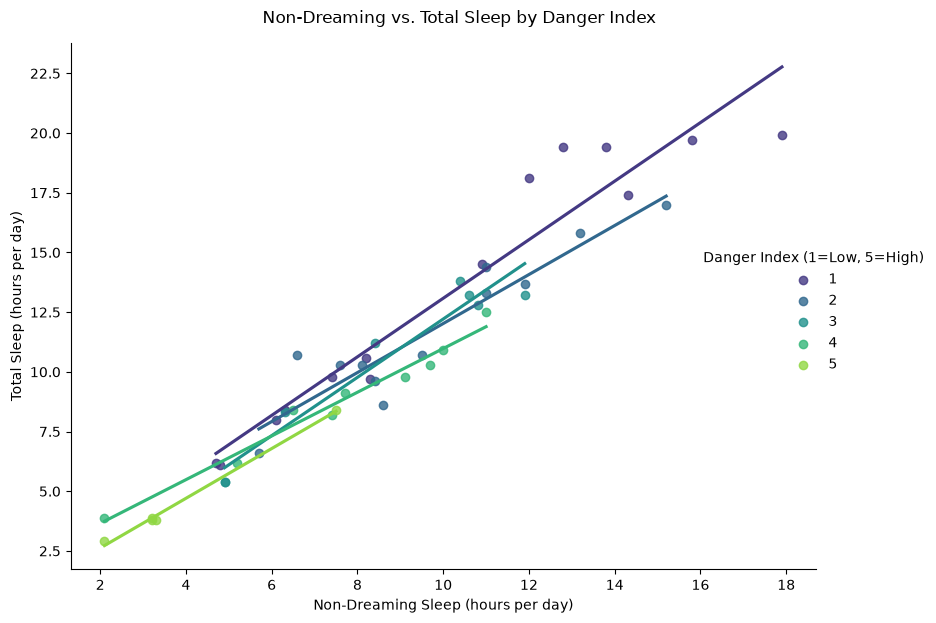

In [19]:
# Plot non-dreaming sleep vs. total sleep by danger index
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    height=6,
    aspect=1.4,
    ci=None
)

g.set_axis_labels(
    "Non-Dreaming Sleep (hours per day)",
    "Total Sleep (hours per day)"
)

g.fig.suptitle("Non-Dreaming vs. Total Sleep by Danger Index", y=1.03)

g._legend.set_title("Danger Index (1=Low, 5=High)")

plt.show()

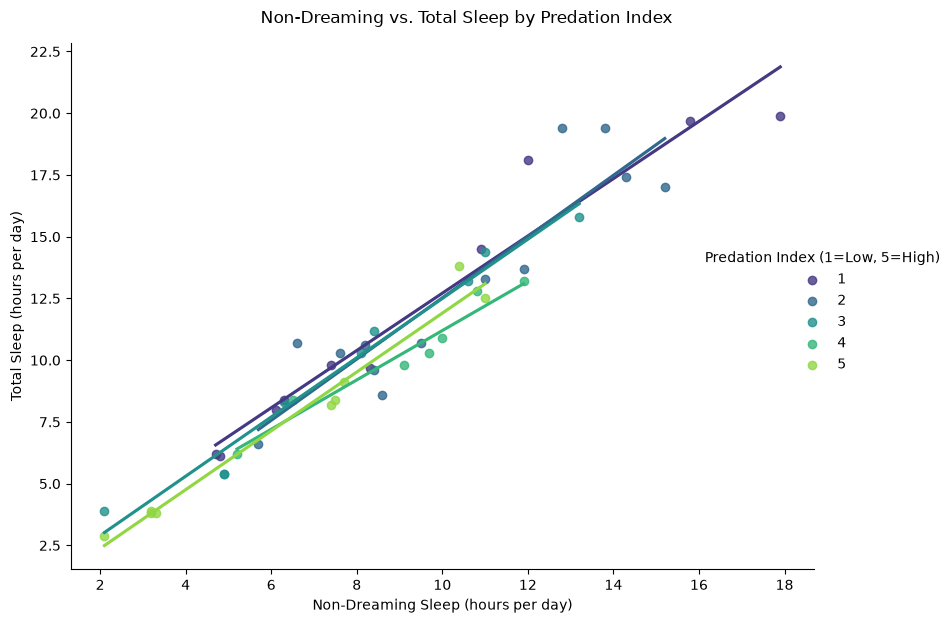

In [20]:
# Plot non-dreaming sleep vs. total sleep by predation index
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    height=6,
    aspect=1.4,
    ci=None
)

g.set_axis_labels(
    "Non-Dreaming Sleep (hours per day)",
    "Total Sleep (hours per day)"
)

g.fig.suptitle("Non-Dreaming vs. Total Sleep by Predation Index", y=1.03)

g._legend.set_title("Predation Index (1=Low, 5=High)")

plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:

Both plots show positive linear relationships with considerable overlap between categories. In the danger index plot, lower danger ratings generally have slightly higher total sleep at comparable non-dreaming-sleep durations. The predation index plot shows a similar pattern, although the regression lines overlap more closely.

The categories provide some additional information, but the differences are relatively small. Group sizes range from 5 to 14 mammals for danger and 7 to 13 for predation. Some categories cover narrower non-dreaming-sleep ranges, making their regression lines less reliable outside those ranges. Overall, non-dreaming sleep remains the strongest visible predictor of total sleep.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [21]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [22]:
# Treat danger and predation ratings as categorical
model_df = sleep_df.copy()

model_df["danger_index"] = model_df["danger_index"].astype("category")
model_df["predation_index"] = model_df["predation_index"].astype("category")

# Calculate R-squared for all four models
phase_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Baseline + Danger",
        "Baseline + Predation",
        "Baseline + Both"
    ],
    "R-squared": [
        calculate_r_squared(
            model_df, "non_dreaming_sleep", "total_sleep", []
        ),
        calculate_r_squared(
            model_df, "non_dreaming_sleep", "total_sleep",
            ["danger_index"]
        ),
        calculate_r_squared(
            model_df, "non_dreaming_sleep", "total_sleep",
            ["predation_index"]
        ),
        calculate_r_squared(
            model_df, "non_dreaming_sleep", "total_sleep",
            ["danger_index", "predation_index"]
        )
    ]
})

# Display the results
display(phase_comparison.round(4))

,Model,R-squared
0,Baseline,0.9268
1,Baseline + Danger,0.9427
2,Baseline + Predation,0.9371
3,Baseline + Both,0.9515


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [23]:
# Display non-dreaming sleep ranges by danger index
print("Danger Index Sleep Ranges:")
display(
    sleep_df.groupby("danger_index", observed=True)["non_dreaming_sleep"]
    .agg(["min", "max"])
)

# Display non-dreaming sleep ranges by predation index
print("Predation Index Sleep Ranges:")
display(
    sleep_df.groupby("predation_index", observed=True)["non_dreaming_sleep"]
    .agg(["min", "max"])
)

Danger Index Sleep Ranges:


,min,max
danger_index,,
1,4.7,17.9
2,5.7,15.2
3,4.9,11.9
4,2.1,11.0
5,2.1,7.5


Predation Index Sleep Ranges:


,min,max
predation_index,,
1,4.7,17.9
2,5.7,15.2
3,2.1,13.2
4,5.2,11.9
5,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer:

Danger groups 1 and 2 have overlapping non-dreaming sleep ranges from 5.7 to 15.2 hours per day. Comparing their regression lines within this range is more reliable because both groups have observations in that interval. Comparing outside this range would require extrapolation, which could produce misleading conclusions.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

Yes, all three additions improve the model slightly. The baseline R-squared is 0.9268. Adding danger increases it to 0.9427 (+0.0159), adding predation increases it to 0.9371 (+0.0103), and adding both increases it to 0.9515 (+0.0247). These are relatively small improvements.

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer:

The group plots show considerable overlap between the danger and predation categories, with only slight differences between their regression lines. This supports the small improvements in R-squared. Non-dreaming sleep remains the strongest predictor, while danger and predation add limited information.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer:

1. The dataset contains only 48 complete records, and some danger and predation categories have very small sample sizes, making their results less reliable.
2. Danger and predation ratings are closely related, so they may provide overlapping information. Additionally, higher R-squared values do not guarantee better predictions for new mammals.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

I predict that total sleep will decrease as gestation time increases. I also expect danger and predation to provide some additional information about sleep duration beyond gestation time.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer:

I expect mammals with longer pregnancies to sleep fewer hours per day. My reasoning is that larger mammals often have longer pregnancies and may need less daily sleep than smaller mammals. I will compare this prediction with the data.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [24]:
# Create gestation_df using the required columns
gestation_df = mammals_df.dropna(
    subset=[
        "gestation_time",
        "total_sleep",
        "danger_index",
        "predation_index"
    ]
).copy()

# Count records
print("Original records:", len(mammals_df))
print("Complete records:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))

# Check gestation time is positive
valid_gestation = (gestation_df["gestation_time"] > 0).all()
print("All gestation times positive:", valid_gestation)

# Check total sleep is between 0 and 24 hours
valid_sleep = gestation_df["total_sleep"].between(0, 24).all()
print("All sleep values within 0–24 hours:", valid_sleep)

# Display minimum and maximum values
display(
    gestation_df[["gestation_time", "total_sleep"]]
    .agg(["min", "max"])
)

# Create logarithm only after validating the data
if valid_gestation and valid_sleep:
    gestation_df["log10_gestation_time"] = np.log10(
        gestation_df["gestation_time"]
    )
    print("Log10 gestation time created successfully.")
else:
    print("Check invalid values before creating the logarithm.")

Original records: 62
Complete records: 54
Records removed: 8
All gestation times positive: True
All sleep values within 0–24 hours: True


,gestation_time,total_sleep
min,12.0,2.6
max,645.0,19.9


Log10 gestation time created successfully.


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

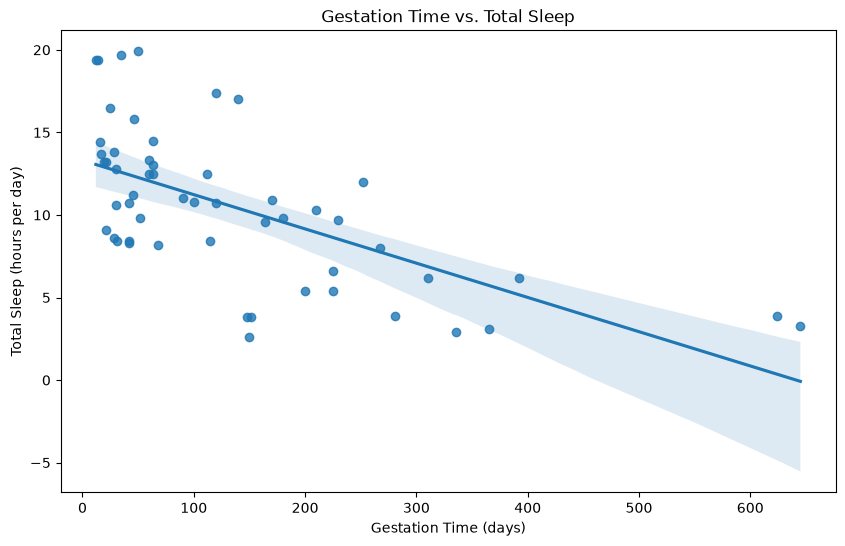

In [25]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=gestation_df,
    x="gestation_time",
    y="total_sleep"
)

plt.title("Gestation Time vs. Total Sleep")
plt.xlabel("Gestation Time (days)")
plt.ylabel("Total Sleep (hours per day)")
plt.show()

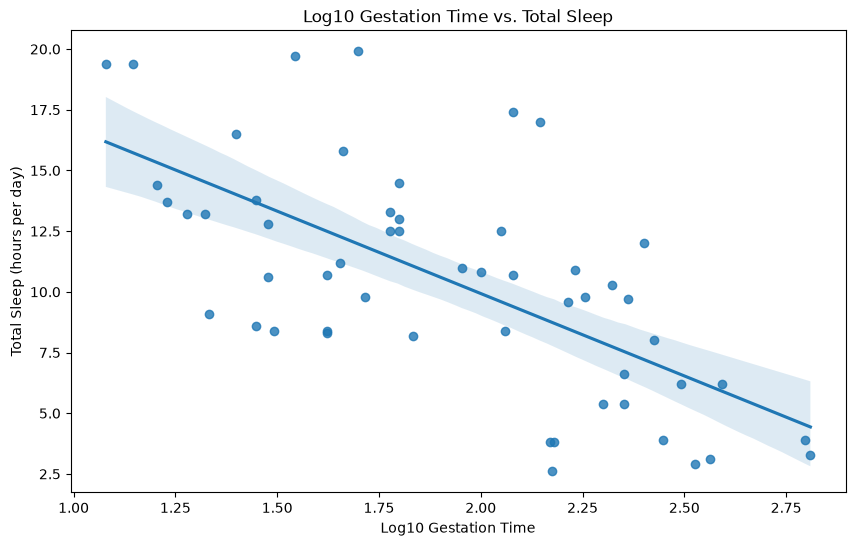

In [26]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep"
)

plt.title("Log10 Gestation Time vs. Total Sleep")
plt.xlabel("Log10 Gestation Time")
plt.ylabel("Total Sleep (hours per day)")
plt.show()

In [27]:
# Original gestation time
r_original = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

# Log10 gestation time
r_log = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

print("Original Gestation vs. Total Sleep")
print(f"Correlation (r): {r_original:.4f}")
print(f"R-squared: {r_original**2:.4f}")

print()

print("Log10 Gestation vs. Total Sleep")
print(f"Correlation (r): {r_log:.4f}")
print(f"R-squared: {r_log**2:.4f}")

Original Gestation vs. Total Sleep
Correlation (r): -0.6313
R-squared: 0.3986

Log10 Gestation vs. Total Sleep
Correlation (r): -0.6637
R-squared: 0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:

The log transformation spreads out shorter gestation times and compresses longer ones, making the negative relationship appear more linear. However, the points remain scattered, so the transformation improves the straight-line summary without removing the variation.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [28]:
print("Danger Index Counts:")
print(gestation_df["danger_index"].value_counts().sort_index())

print("\nPredation Index Counts:")
print(gestation_df["predation_index"].value_counts().sort_index())

Danger Index Counts:
danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

Predation Index Counts:
predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64


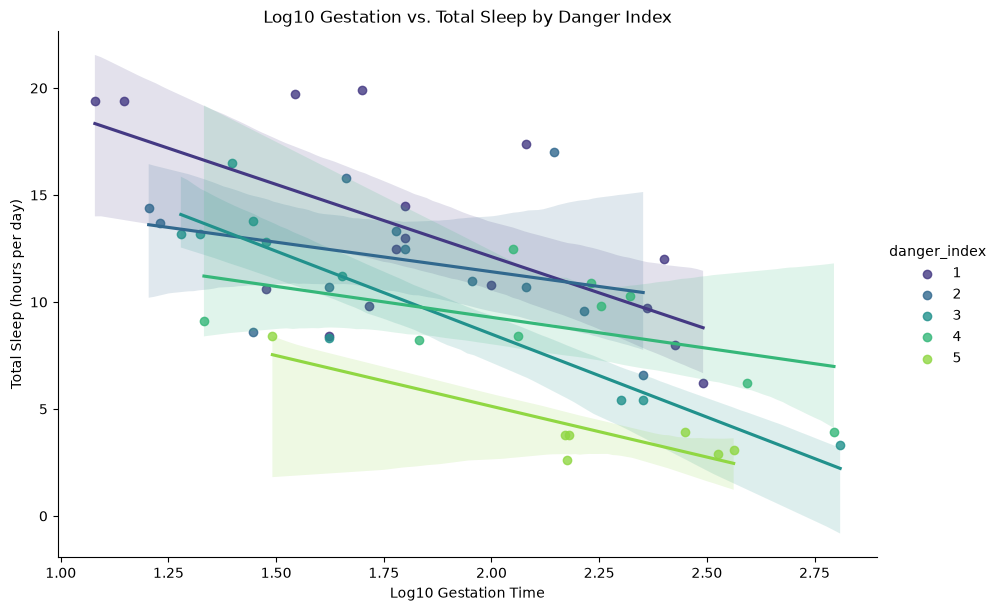

In [29]:
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    height=6,
    aspect=1.5
)

plt.title("Log10 Gestation vs. Total Sleep by Danger Index")
plt.xlabel("Log10 Gestation Time")
plt.ylabel("Total Sleep (hours per day)")
plt.show()

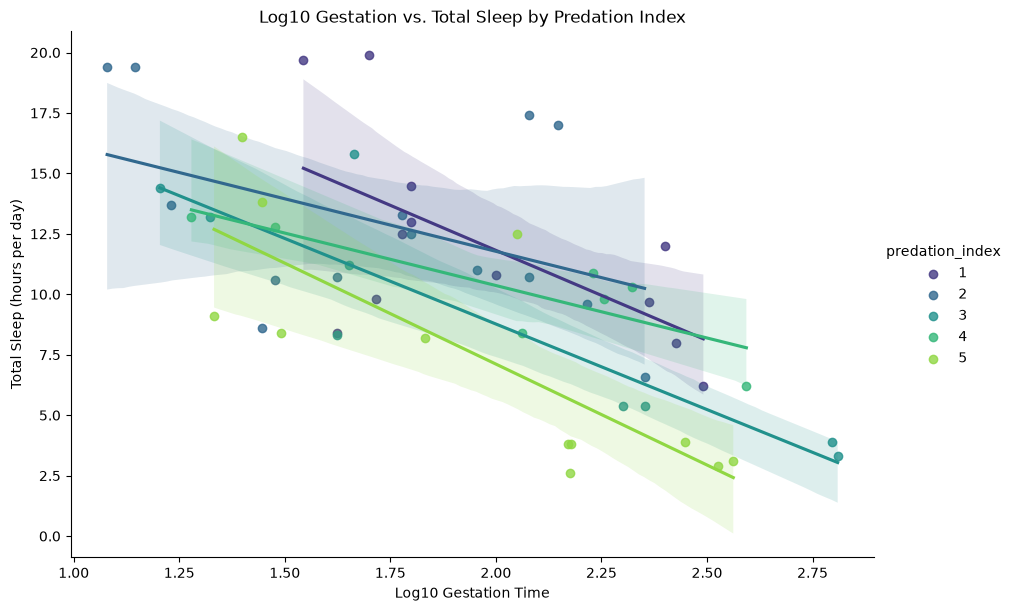

In [30]:
sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    height=6,
    aspect=1.5
)

plt.title("Log10 Gestation vs. Total Sleep by Predation Index")
plt.xlabel("Log10 Gestation Time")
plt.ylabel("Total Sleep (hours per day)")
plt.show()

In [31]:
models = [
    ("Baseline", []),
    ("Baseline + Danger", ["danger_index"]),
    ("Baseline + Predation", ["predation_index"]),
    ("Baseline + Both", ["danger_index", "predation_index"])
]

results = []

for name, features in models:
    r2 = calculate_r_squared(
        gestation_df,
        "log10_gestation_time",
        "total_sleep",
        features
    )
    results.append({"Model": name, "R-squared": round(r2, 4)})

sleep_comparison = pd.DataFrame(results)

display(sleep_comparison)

,Model,R-squared
0,Baseline,0.4404
1,Baseline + Danger,0.6542
2,Baseline + Predation,0.5917
3,Baseline + Both,0.6943


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [32]:
# Select the first five records
log_check = gestation_df[
    ["species", "gestation_time", "log10_gestation_time"]
].head().copy()

# Reverse the logarithm
log_check["recovered_days"] = 10 ** log_check["log10_gestation_time"]

# Check whether the values match
log_check["matches"] = np.isclose(
    log_check["gestation_time"],
    log_check["recovered_days"]
)

display(log_check)

,species,gestation_time,log10_gestation_time,recovered_days,matches
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


In [33]:
# Find the shortest and longest gestation times
shortest = gestation_df.nsmallest(1, "gestation_time")
longest = gestation_df.nlargest(1, "gestation_time")

# Combine the records
extreme_gestation = pd.concat([shortest, longest])

# Display their measurements
display(
    extreme_gestation[
        ["species", "gestation_time", "log10_gestation_time", "total_sleep"]
    ]
)

,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4
0,African elephant,645.0,2.809560,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer:

Yes, reversing the logarithm recovered the original gestation times for all five records. Both plots show the North American opossum sleeping 19.4 hours with a 12-day gestation and the African elephant sleeping 3.3 hours with a 645-day gestation. The logarithm changed their horizontal positions but did not change their total sleep values or vertical positions.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer:

Mammals with longer gestation times generally sleep fewer hours per day. The log transformation made the negative relationship appear more linear, although scatter remained. The log-gestation model had an R-squared of 0.4404. Adding danger increased it to 0.6542, while adding predation increased it to 0.5917. Including both produced the highest R-squared of 0.6943. The group plots also showed differences between danger and predation levels. These results support my prediction that mammals with longer pregnancies tend to sleep less.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:

Two limitations are the small dataset of 54 mammals and the uneven number of observations across danger and predation categories. These limitations make the results less reliable for predicting sleep patterns in other mammals.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

I used ChatGPT for assistance with the lab. I checked its suggestions against my notebook results and confirmed that the graphs and calculations matched the data.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.